# Coding Assignment 2: What can a traveller learn from a year of flights?

In [1]:
import pandas as pd
import plotnine as pn

flights = pd.read_csv("data/flights.csv.zip")
airlines = pd.read_csv("data/airlines.csv")


## 1. Build the analysis sample

### 1(a) What one row represents, shapes, type and duplicates

In `flights`, one row is one scheduled flight record: one flight on one date, from one origin airport to one destination. In `airlines`, one row is one carrier code and its full airline name.

Flight numbers recur on different dates, so a repeated flight number is not by itself a duplicate. Only exact duplicate rows across all original columns would need removing.

In [2]:
print("flights (rows, columns):", flights.shape)
print("airlines (rows, columns):", airlines.shape)
print("arr_delay type:", flights["arr_delay"].dtype)
print("exact duplicate flight rows:", flights.duplicated().sum())

flights (rows, columns): (336776, 19)
airlines (rows, columns): (16, 2)
arr_delay type: float64
exact duplicate flight rows: 0


There are no exact duplicate rows, so no rows are removed.

### 1(b) Known and missing arrival delays, and the late-arrival indicator

In [3]:
# True for a delay of 15 minutes or more; where keeps missing delays missing
flights["late_arrival"] = (flights["arr_delay"] >= 15).where(
    flights["arr_delay"].notna()
)
missing_arrival_delay = flights["arr_delay"].isna()

print("flights with known arrival delay:", (~missing_arrival_delay).sum())
print("flights with missing arrival delay:", missing_arrival_delay.sum())
print("flights in total:", len(flights))
print("the two counts add up to the total:", (~missing_arrival_delay).sum() + missing_arrival_delay.sum() == len(flights))


flights with known arrival delay: 327346
flights with missing arrival delay: 9430
flights in total: 336776
the two counts add up to the total: True


The rule applied to an early arrival, 14 minutes, exactly 15 minutes and a missing value:

In [4]:
late_rule_examples = pd.DataFrame({"arr_delay": [-5, 14, 15, None]})
late_rule_examples["late_arrival"] = (late_rule_examples["arr_delay"] >= 15).where(
    late_rule_examples["arr_delay"].notna()
)
print(late_rule_examples.to_string(index=False))


 arr_delay late_arrival
      -5.0        False
      14.0        False
      15.0         True
       NaN          NaN


## 2. Attach the airline names

In [5]:
print("lookup codes:", len(airlines), "| each code occurs once:", airlines["carrier"].is_unique)
print("flights before join:", len(flights))

flights_with_airline_names = flights.merge(airlines, on="carrier", how="left", validate="many_to_one")
print("flights after join:", len(flights_with_airline_names))
print("flights with unmatched carrier code:", flights_with_airline_names["name"].isna().sum())

lookup codes: 16 | each code occurs once: True
flights before join: 336776
flights after join: 336776
flights with unmatched carrier code: 0


## 3. Give the editor a table they can check

### 3(a) Five busiest airlines and all airlines combined

In [6]:
airline_summary_by_carrier = flights_with_airline_names.groupby(["carrier", "name"], as_index=False).agg(
    scheduled_flights=("carrier", "size"),
    known_arrivals=("late_arrival", "count"),
    late_arrivals=("late_arrival", "sum"),
)
top_five_airlines = airline_summary_by_carrier.sort_values("scheduled_flights", ascending=False).head(5)
top_five_airlines = top_five_airlines[["name", "scheduled_flights", "known_arrivals", "late_arrivals"]]

all_airlines_row = pd.DataFrame({
    "name": ["All airlines combined"],
    "scheduled_flights": [len(flights_with_airline_names)],
    "known_arrivals": [flights_with_airline_names["late_arrival"].count()],
    "late_arrivals": [flights_with_airline_names["late_arrival"].sum()],
})

airline_summary = pd.concat([top_five_airlines, all_airlines_row], ignore_index=True)
airline_summary["late_arrivals"] = pd.to_numeric(airline_summary["late_arrivals"])
airline_summary["percent_late"] = 100 * airline_summary["late_arrivals"] / airline_summary["known_arrivals"]

display_table = airline_summary.rename(columns={
    "name": "Airline",
    "scheduled_flights": "Scheduled flights",
    "known_arrivals": "Flights with known arrival delay",
    "late_arrivals": "Late arrivals (15+ min)",
    "percent_late": "Percent late (%)",
})
print(display_table.round({"Percent late (%)": 1}).to_string(index=False))

                 Airline  Scheduled flights  Flights with known arrival delay  Late arrivals (15+ min)  Percent late (%)
   United Air Lines Inc.              58665                             57782                    13004              22.5
         JetBlue Airways              54635                             54049                    14567              27.0
ExpressJet Airlines Inc.              54173                             51108                    16399              32.1
    Delta Air Lines Inc.              48110                             47658                     9038              19.0
  American Airlines Inc.              32729                             31947                     6203              19.4
   All airlines combined             336776                            327346                    80100              24.5


### 3(b) Recompute one airline from its flight records

In [7]:
united_flights = flights_with_airline_names.loc[flights_with_airline_names["carrier"] == "UA"]
united_late_arrivals = (united_flights["arr_delay"] >= 15).sum()
united_known_arrivals = united_flights["arr_delay"].notna().sum()
print("United late arrivals (15+ min):", united_late_arrivals)
print("United flights with known arrival delay:", united_known_arrivals)
print(f"percent late: {united_late_arrivals} / {united_known_arrivals} = {100 * united_late_arrivals / united_known_arrivals:.1f}%")

united_summary_row = airline_summary.loc[airline_summary["name"] == "United Air Lines Inc."].iloc[0]
print("table row:", united_summary_row["late_arrivals"], "/", united_summary_row["known_arrivals"], "=", round(united_summary_row["percent_late"], 1), "%")
late_count_matches_table = united_late_arrivals == united_summary_row["late_arrivals"]
known_count_matches_table = united_known_arrivals == united_summary_row["known_arrivals"]
print("agrees with the table:", late_count_matches_table and known_count_matches_table)

United late arrivals (15+ min): 13004
United flights with known arrival delay: 57782
percent late: 13004 / 57782 = 22.5%
table row: 13004 / 57782 = 22.5 %
agrees with the table: True


### 3(c) Alternative denominator: all scheduled flights

In [8]:
total_late_arrivals = flights_with_airline_names["late_arrival"].sum()
total_known_arrivals = flights_with_airline_names["late_arrival"].count()
total_scheduled_flights = len(flights_with_airline_names)

headline_rate = 100 * total_late_arrivals / total_known_arrivals
all_scheduled_rate = 100 * total_late_arrivals / total_scheduled_flights
print(f"headline, known arrival delays: {total_late_arrivals:,} / {total_known_arrivals:,} = {headline_rate:.2f}%")
print(f"alternative, all scheduled flights: {total_late_arrivals:,} / {total_scheduled_flights:,} = {all_scheduled_rate:.2f}%")
print(f"change: {all_scheduled_rate - headline_rate:+.2f} percentage points")

headline, known arrival delays: 80,100 / 327,346 = 24.47%
alternative, all scheduled flights: 80,100 / 336,776 = 23.78%
change: -0.69 percentage points


The alternative denominator counts every scheduled flight record, including flights with no arrival delay recorded. Those flights are not counted as late, so the rate falls.

## 4. Pitch and illustrate your own finding

### 4(a) The pitch

**Reader:** a traveller departing from one of New York’s airports who wants to know whether a delayed flight is likely to arrive late.

**Question:** Among flights leaving New York, how does the share arriving at least 15 minutes late change across departure-delay bands, and how does the pattern differ by airport? This is about the same flight’s arrival, not whether a passenger misses an onward connection.

**Measure:** the share of flights with known departure and arrival delays whose arrival delay is 15 minutes or more. Bands by departure delay: 0 or early, 1–14, 15–29, 30–59 and 60+ minutes. The 15-minute arrival cutoff matches Question 1.


In [9]:
has_both_delays = flights_with_airline_names["dep_delay"].notna() & flights_with_airline_names["arr_delay"].notna()
flights_for_figure = flights_with_airline_names.loc[has_both_delays].copy()
flights_for_figure["late_arrival"] = flights_for_figure["arr_delay"] >= 15

departure_delay_bands = ["0 or early", "1-14", "15-29", "30-59", "60+"]
flights_for_figure["departure_band"] = None
flights_for_figure.loc[flights_for_figure["dep_delay"] <= 0, "departure_band"] = departure_delay_bands[0]
flights_for_figure.loc[
    (flights_for_figure["dep_delay"] > 0) & (flights_for_figure["dep_delay"] < 15),
    "departure_band",
] = departure_delay_bands[1]
flights_for_figure.loc[
    (flights_for_figure["dep_delay"] >= 15) & (flights_for_figure["dep_delay"] < 30),
    "departure_band",
] = departure_delay_bands[2]
flights_for_figure.loc[
    (flights_for_figure["dep_delay"] >= 30) & (flights_for_figure["dep_delay"] < 60),
    "departure_band",
] = departure_delay_bands[3]
flights_for_figure.loc[flights_for_figure["dep_delay"] >= 60, "departure_band"] = departure_delay_bands[4]

print("flights behind the figure:", len(flights_for_figure))


flights behind the figure: 327346


### 4(b) First version of the figure

In [10]:
late_arrivals_by_band_and_airport = flights_for_figure.groupby(["departure_band", "origin"], as_index=False).agg(
    flights=("late_arrival", "size"),
    share_late=("late_arrival", "mean"),
)
late_arrivals_by_band_and_airport["departure_band"] = pd.Categorical(
    late_arrivals_by_band_and_airport["departure_band"], categories=departure_delay_bands, ordered=True
)
late_arrivals_by_band_and_airport = late_arrivals_by_band_and_airport.sort_values(["departure_band", "origin"])
late_arrivals_by_band_and_airport["share_late_pct"] = 100 * late_arrivals_by_band_and_airport["share_late"]

first_figure = (
    pn.ggplot(late_arrivals_by_band_and_airport, pn.aes("departure_band", "share_late_pct"))
    + pn.geom_col(fill="#245b78")
    + pn.facet_wrap("~origin", ncol=3)
    + pn.labs(
        title="Flights with longer departure delays are more often late on arrival",
        x="Departure delay band (minutes)",
        y="Share arriving 15+ min late (%)",
    )
)
first_figure


### 4(c) Final version: replace bars with points, keeping airport facets


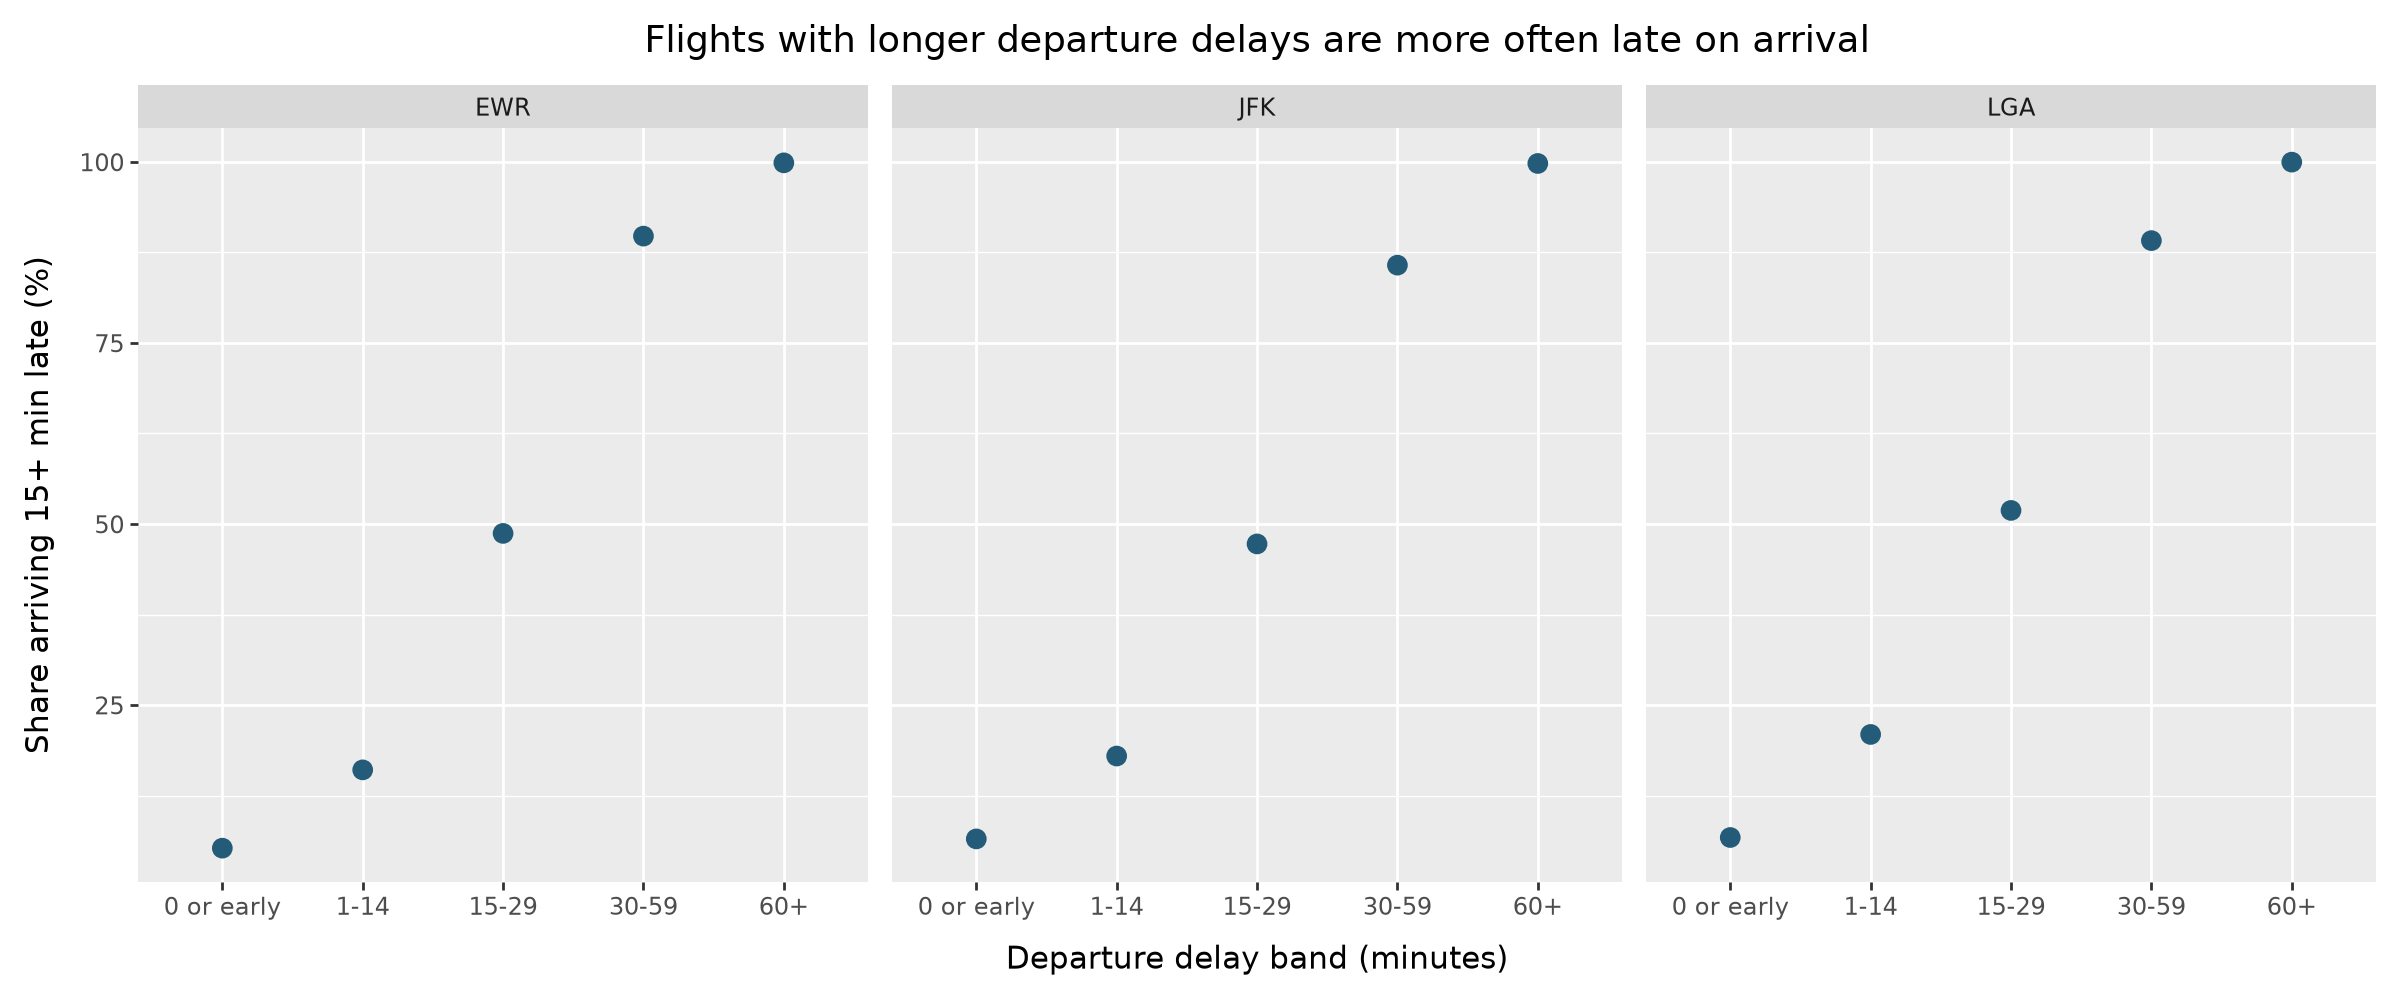

In [11]:
final_figure = (
    pn.ggplot(late_arrivals_by_band_and_airport, pn.aes("departure_band", "share_late_pct"))
    + pn.geom_point(color="#245b78", size=3.2)
    + pn.facet_wrap("~origin", ncol=3)
    + pn.labs(
        title="Flights with longer departure delays are more often late on arrival",
        x="Departure delay band (minutes)",
        y="Share arriving 15+ min late (%)",
    )
)
final_figure


In [12]:
final_figure.save("figure.png", width=12, height=5, dpi=200, verbose=False)


**The edit.** Replacing the bars with points makes the upward pattern across ordered departure-delay bands easier to compare at each airport. The points no longer emphasize each group’s magnitude from a zero baseline, so exact shares are less immediate and should be read against the y-axis.


### 4(d) Numbers for the caption

In [13]:
late_arrivals_by_departure_band = flights_for_figure.groupby("departure_band", as_index=False).agg(
    flights=("late_arrival", "size"),
    share_late=("late_arrival", "mean"),
)
late_arrivals_by_departure_band["departure_band"] = pd.Categorical(
    late_arrivals_by_departure_band["departure_band"], categories=departure_delay_bands, ordered=True
)
late_arrivals_by_departure_band = late_arrivals_by_departure_band.sort_values("departure_band")
late_arrivals_by_departure_band["share_late_pct"] = (100 * late_arrivals_by_departure_band["share_late"]).round(1)
print(late_arrivals_by_departure_band.to_string(index=False))
print("total flights:", late_arrivals_by_departure_band["flights"].sum())

departure_band  flights  share_late  share_late_pct
    0 or early   199601    0.061678             6.2
          1-14    55325    0.179160            17.9
         15-29    23396    0.490810            49.1
         30-59    22222    0.883179            88.3
           60+    26802    0.998731            99.9
total flights: 327346


Among 327,346 flights departing EWR, JFK or LGA in 2013 with known departure and arrival delays, 6.2% of flights that left early or on time arrived at least 15 minutes late. The share is 49.1% for flights departing 15–29 minutes late and 99.9% for those departing 60 or more minutes late. Source: nycflights13, based on U.S. Bureau of Transportation Statistics records, January–December 2013. These flight-level associations do not establish that departure delay caused arrival delay, and the data do not identify onward connections.
